In [8]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

print("Libraries imported successfully!")

Libraries imported successfully!


In [9]:
file_path = "/content/HHS_Unaccompanied_Alien_Children_Program (1).csv"

df = pd.read_csv(file_path)

print("Dataset loaded successfully!")

Dataset loaded successfully!


In [10]:
df.head()

,Date,Children apprehended and placed in CBP custody*,Children in CBP custody,Children transferred out of CBP custody,Children in HHS Care,Children discharged from HHS Care
0,"December 21, 2025",6.0,18.0,11.0,"2,484",14.0
1,"December 18, 2025",11.0,50.0,6.0,"2,472",16.0
2,"December 17, 2025",7.0,31.0,11.0,"2,481",10.0
3,"December 16, 2025",8.0,54.0,15.0,"2,468",9.0
4,"December 15, 2025",11.0,42.0,9.0,"2,470",7.0


In [14]:
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

Rows: 720
Columns: 15


In [15]:
print("Column names:\n")

for i, column in enumerate(df.columns, start=1):
    print(i, "→", column)

Column names:

1 → Date
2 → Children apprehended and placed in CBP custody*
3 → Children in CBP custody
4 → Children transferred out of CBP custody
5 → Children in HHS Care
6 → Children discharged from HHS Care
7 → Total System Load
8 → 7-Observation Average
9 → 14-Observation Average
10 → Net Intake Pressure
11 → Care Load Growth Rate (%)
12 → 7-Day Average Load
13 → 14-Day Average Load
14 → Care Load Volatility
15 → Discharge Offset Ratio


In [16]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 720 entries, 0 to 719
Data columns (total 15 columns):
 #   Column                                           Non-Null Count  Dtype         
---  ------                                           --------------  -----         
 0   Date                                             720 non-null    datetime64[ns]
 1   Children apprehended and placed in CBP custody*  720 non-null    float64       
 2   Children in CBP custody                          720 non-null    float64       
 3   Children transferred out of CBP custody          720 non-null    float64       
 4   Children in HHS Care                             720 non-null    int64         
 5   Children discharged from HHS Care                720 non-null    float64       
 6   Total System Load                                720 non-null    float64       
 7   7-Observation Average                            714 non-null    float64       
 8   14-Observation Average                  

In [17]:
df["Date"] = pd.to_datetime(df["Date"], errors="coerce")

print("Date converted successfully!")

Date converted successfully!


In [18]:
print("Earliest date:", df["Date"].min())
print("Latest date:", df["Date"].max())

Earliest date: 2023-01-12 00:00:00
Latest date: 2025-12-21 00:00:00


In [19]:
df = df.sort_values("Date").reset_index(drop=True)

df.head()

,Date,Children apprehended and placed in CBP custody*,Children in CBP custody,Children transferred out of CBP custody,Children in HHS Care,Children discharged from HHS Care,Total System Load,7-Observation Average,14-Observation Average,Net Intake Pressure,Care Load Growth Rate (%),7-Day Average Load,14-Day Average Load,Care Load Volatility,Discharge Offset Ratio
0,2023-01-12,33.0,53.0,34.0,6566,436.0,6619.0,NaN,NaN,-402.0,NaN,NaN,NaN,NaN,12.823529
1,2023-01-22,32.0,49.0,39.0,7122,227.0,7171.0,NaN,NaN,-188.0,8.339628,NaN,NaN,NaN,5.820513
2,2023-01-23,32.0,50.0,39.0,7280,181.0,7330.0,NaN,NaN,-142.0,2.217264,NaN,NaN,NaN,4.641026
3,2023-01-24,47.0,42.0,47.0,7433,175.0,7475.0,NaN,NaN,-128.0,1.978172,NaN,NaN,NaN,3.723404
4,2023-01-25,20.0,22.0,41.0,7538,180.0,7560.0,NaN,NaN,-139.0,1.137124,NaN,NaN,NaN,4.390244


In [20]:
print("Missing values:")
print(df.isnull().sum())

Missing values:
Date                                                0
Children apprehended and placed in CBP custody*     0
Children in CBP custody                             0
Children transferred out of CBP custody             0
Children in HHS Care                                0
Children discharged from HHS Care                   0
Total System Load                                   0
7-Observation Average                               6
14-Observation Average                             13
Net Intake Pressure                                 0
Care Load Growth Rate (%)                           1
7-Day Average Load                                  6
14-Day Average Load                                13
Care Load Volatility                                6
Discharge Offset Ratio                              3
dtype: int64


In [21]:
print("Duplicate dates:", df["Date"].duplicated().sum())

Duplicate dates: 0


In [22]:
full_dates = pd.date_range(
    start=df["Date"].min(),
    end=df["Date"].max(),
    freq="D"
)

missing_dates = full_dates.difference(df["Date"])

print("Expected daily dates:", len(full_dates))
print("Actual dates:", df["Date"].nunique())
print("Missing dates:", len(missing_dates))

Expected daily dates: 1075
Actual dates: 720
Missing dates: 355


In [23]:
print(missing_dates)

DatetimeIndex(['2023-01-13', '2023-01-14', '2023-01-15', '2023-01-16',
               '2023-01-17', '2023-01-18', '2023-01-19', '2023-01-20',
               '2023-01-21', '2023-01-26',
               ...
               '2025-11-22', '2025-11-26', '2025-11-28', '2025-11-29',
               '2025-12-05', '2025-12-06', '2025-12-12', '2025-12-13',
               '2025-12-19', '2025-12-20'],
              dtype='datetime64[ns]', length=355, freq=None)


In [24]:
# Remove rows where Date is missing
df = df.dropna(subset=["Date"]).copy()

# Reset the row numbers
df = df.reset_index(drop=True)

print("Rows after removing empty rows:", len(df))
print("Columns:", len(df.columns))

Rows after removing empty rows: 720
Columns: 15


In [25]:
print(df.isnull().sum())

Date                                                0
Children apprehended and placed in CBP custody*     0
Children in CBP custody                             0
Children transferred out of CBP custody             0
Children in HHS Care                                0
Children discharged from HHS Care                   0
Total System Load                                   0
7-Observation Average                               6
14-Observation Average                             13
Net Intake Pressure                                 0
Care Load Growth Rate (%)                           1
7-Day Average Load                                  6
14-Day Average Load                                13
Care Load Volatility                                6
Discharge Offset Ratio                              3
dtype: int64


In [26]:
df["Children in HHS Care"] = pd.to_numeric(
    df["Children in HHS Care"],
    errors="coerce"
)

In [27]:
print(df.dtypes)

Date                                               datetime64[ns]
Children apprehended and placed in CBP custody*           float64
Children in CBP custody                                   float64
Children transferred out of CBP custody                   float64
Children in HHS Care                                        int64
Children discharged from HHS Care                         float64
Total System Load                                         float64
7-Observation Average                                     float64
14-Observation Average                                    float64
Net Intake Pressure                                       float64
Care Load Growth Rate (%)                                 float64
7-Day Average Load                                        float64
14-Day Average Load                                       float64
Care Load Volatility                                      float64
Discharge Offset Ratio                                    float64
dtype: obj

In [28]:
print("Earliest date:", df["Date"].min())
print("Latest date:", df["Date"].max())

Earliest date: 2023-01-12 00:00:00
Latest date: 2025-12-21 00:00:00


In [29]:
print("Duplicate dates:", df["Date"].duplicated().sum())

Duplicate dates: 0


In [30]:
full_dates = pd.date_range(
    start=df["Date"].min(),
    end=df["Date"].max(),
    freq="D"
)

missing_dates = full_dates.difference(df["Date"])

print("Expected daily dates:", len(full_dates))
print("Actual dates:", df["Date"].nunique())
print("Missing dates:", len(missing_dates))

Expected daily dates: 1075
Actual dates: 720
Missing dates: 355


In [31]:
print(missing_dates)

DatetimeIndex(['2023-01-13', '2023-01-14', '2023-01-15', '2023-01-16',
               '2023-01-17', '2023-01-18', '2023-01-19', '2023-01-20',
               '2023-01-21', '2023-01-26',
               ...
               '2025-11-22', '2025-11-26', '2025-11-28', '2025-11-29',
               '2025-12-05', '2025-12-06', '2025-12-12', '2025-12-13',
               '2025-12-19', '2025-12-20'],
              dtype='datetime64[ns]', length=355, freq=None)


In [32]:

#  CREATE PROJECT KPIs


# 1. Total System Load
df["Total System Load"] = (
    df["Children in CBP custody"] +
    df["Children in HHS Care"]
)

# 2. Net Intake Pressure
df["Net Intake Pressure"] = (
    df["Children transferred out of CBP custody"] -
    df["Children discharged from HHS Care"]
)

# 3. Care Load Growth Rate
df["Care Load Growth Rate (%)"] = (
    df["Total System Load"].pct_change() * 100
)

# 4. 7-Day Rolling Average
df["7-Day Average Load"] = (
    df["Total System Load"].rolling(window=7).mean()
)

# 5. 14-Day Rolling Average
df["14-Day Average Load"] = (
    df["Total System Load"].rolling(window=14).mean()
)

# 6. Care Load Volatility
df["Care Load Volatility"] = (
    df["Total System Load"].rolling(window=7).std()
)

# 7. Discharge Offset Ratio
df["Discharge Offset Ratio"] = np.where(
    df["Children transferred out of CBP custody"] > 0,
    df["Children discharged from HHS Care"] /
    df["Children transferred out of CBP custody"],
    np.nan
)

# Display results
df.head()

,Date,Children apprehended and placed in CBP custody*,Children in CBP custody,Children transferred out of CBP custody,Children in HHS Care,Children discharged from HHS Care,Total System Load,7-Observation Average,14-Observation Average,Net Intake Pressure,Care Load Growth Rate (%),7-Day Average Load,14-Day Average Load,Care Load Volatility,Discharge Offset Ratio
0,2023-01-12,33.0,53.0,34.0,6566,436.0,6619.0,NaN,NaN,-402.0,NaN,NaN,NaN,NaN,12.823529
1,2023-01-22,32.0,49.0,39.0,7122,227.0,7171.0,NaN,NaN,-188.0,8.339628,NaN,NaN,NaN,5.820513
2,2023-01-23,32.0,50.0,39.0,7280,181.0,7330.0,NaN,NaN,-142.0,2.217264,NaN,NaN,NaN,4.641026
3,2023-01-24,47.0,42.0,47.0,7433,175.0,7475.0,NaN,NaN,-128.0,1.978172,NaN,NaN,NaN,3.723404
4,2023-01-25,20.0,22.0,41.0,7538,180.0,7560.0,NaN,NaN,-139.0,1.137124,NaN,NaN,NaN,4.390244


In [33]:
kpi_columns = [
    "Date",
    "Total System Load",
    "Net Intake Pressure",
    "Care Load Growth Rate (%)",
    "7-Day Average Load",
    "14-Day Average Load",
    "Care Load Volatility",
    "Discharge Offset Ratio"
]

df[kpi_columns].head(15)

,Date,Total System Load,Net Intake Pressure,Care Load Growth Rate (%),7-Day Average Load,14-Day Average Load,Care Load Volatility,Discharge Offset Ratio
0,2023-01-12,6619.0,-402.0,NaN,NaN,NaN,NaN,12.823529
1,2023-01-22,7171.0,-188.0,8.339628,NaN,NaN,NaN,5.820513
2,2023-01-23,7330.0,-142.0,2.217264,NaN,NaN,NaN,4.641026
3,2023-01-24,7475.0,-128.0,1.978172,NaN,NaN,NaN,3.723404
4,2023-01-25,7560.0,-139.0,1.137124,NaN,NaN,NaN,4.390244
5,2023-01-29,7517.0,-292.0,-0.568783,NaN,NaN,NaN,27.545455
6,2023-01-30,7797.0,-167.0,3.724890,7352.714286,NaN,377.309208,6.758621
7,2023-01-31,7839.0,-122.0,0.538669,7527.000000,NaN,237.936266,4.388889
8,2023-02-01,7935.0,-204.0,1.224646,7636.142857,NaN,222.120409,8.555556
9,2023-02-02,7892.0,-275.0,-0.541903,7716.428571,NaN,192.632515,12.956522


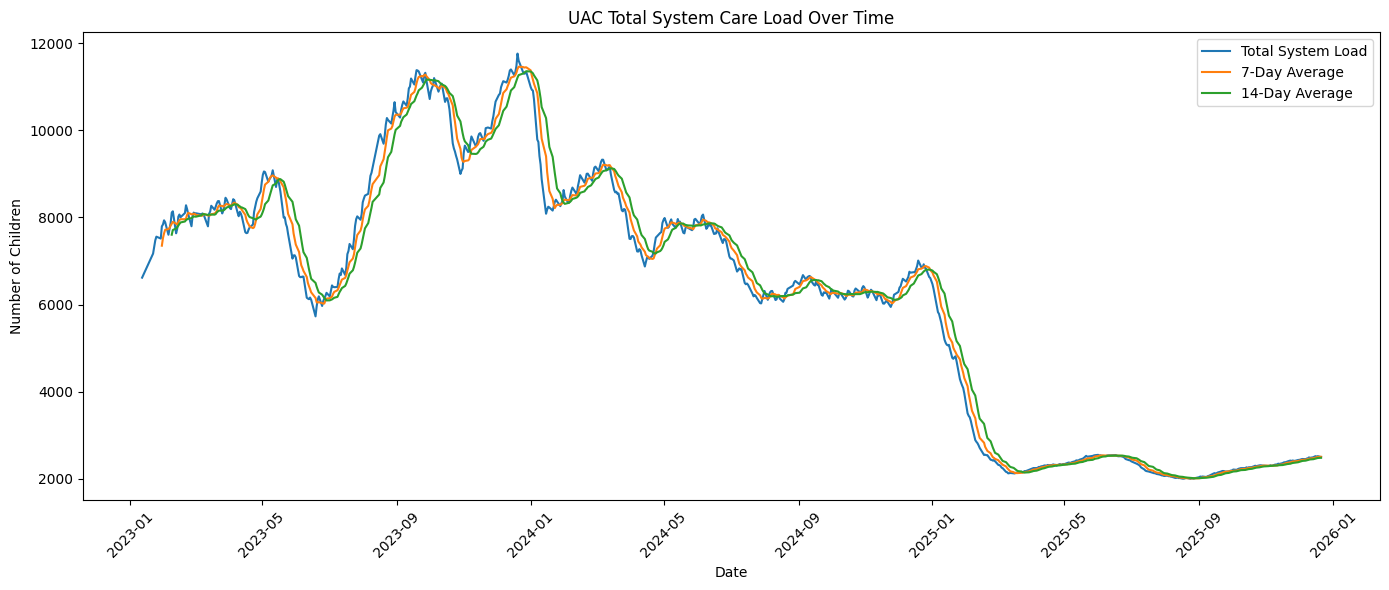

In [34]:
plt.figure(figsize=(14, 6))

plt.plot(
    df["Date"],
    df["Total System Load"],
    label="Total System Load"
)

plt.plot(
    df["Date"],
    df["7-Day Average Load"],
    label="7-Day Average"
)

plt.plot(
    df["Date"],
    df["14-Day Average Load"],
    label="14-Day Average"
)

plt.xlabel("Date")
plt.ylabel("Number of Children")
plt.title("UAC Total System Care Load Over Time")

plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()

plt.show()

In [35]:
# 1. Clean the commas out of the string column first
df["Children in HHS Care"] = (
    df["Children in HHS Care"].astype(str).str.replace(",", "")
)

# 2. Convert to numeric safely
df["Children in HHS Care"] = pd.to_numeric(
    df["Children in HHS Care"], errors="coerce"
)

# 3. Recalculate Total System Load
df["Total System Load"] = (
    df["Children in CBP custody"] + df["Children in HHS Care"]
)

# 4. Recalculate rolling averages
df["7-Observation Average"] = (
    df["Total System Load"].rolling(window=7).mean()
)
df["14-Observation Average"] = (
    df["Total System Load"].rolling(window=14).mean()
)

In [36]:
print("Total System Load:")
print(df["Total System Load"].head(10))

print("\nCBP Custody:")
print(df["Children in CBP custody"].head(10))

print("\nHHS Care:")
print(df["Children in HHS Care"].head(10))

print("\nData types:")
print(df[[
    "Children in CBP custody",
    "Children in HHS Care",
    "Total System Load"
]].dtypes)

print("\nMissing values:")
print(df[[
    "Children in CBP custody",
    "Children in HHS Care",
    "Total System Load"
]].isna().sum())

print("\nSummary:")
print(df[[
    "Children in CBP custody",
    "Children in HHS Care",
    "Total System Load"
]].describe())

Total System Load:
0    6619.0
1    7171.0
2    7330.0
3    7475.0
4    7560.0
5    7517.0
6    7797.0
7    7839.0
8    7935.0
9    7892.0
Name: Total System Load, dtype: float64

CBP Custody:
0    53.0
1    49.0
2    50.0
3    42.0
4    22.0
5    45.0
6    54.0
7    36.0
8    32.0
9    13.0
Name: Children in CBP custody, dtype: float64

HHS Care:
0    6566
1    7122
2    7280
3    7433
4    7538
5    7472
6    7743
7    7803
8    7903
9    7879
Name: Children in HHS Care, dtype: int64

Data types:
Children in CBP custody    float64
Children in HHS Care         int64
Total System Load          float64
dtype: object

Missing values:
Children in CBP custody    0
Children in HHS Care       0
Total System Load          0
dtype: int64

Summary:
       Children in CBP custody  Children in HHS Care  Total System Load
count               720.000000            720.000000         720.000000
mean                171.494444           6061.275000        6232.769444
std                 126.354965    

In [37]:
df["Children in CBP custody"] = pd.to_numeric(
    df["Children in CBP custody"], errors="coerce"
)

df["Children in HHS Care"] = pd.to_numeric(
    df["Children in HHS Care"], errors="coerce"
)

df["Total System Load"] = (
    df["Children in CBP custody"] +
    df["Children in HHS Care"]
)

print(df[[
    "Date",
    "Children in CBP custody",
    "Children in HHS Care",
    "Total System Load"
]].head(10))

        Date  Children in CBP custody  Children in HHS Care  Total System Load
0 2023-01-12                     53.0                  6566             6619.0
1 2023-01-22                     49.0                  7122             7171.0
2 2023-01-23                     50.0                  7280             7330.0
3 2023-01-24                     42.0                  7433             7475.0
4 2023-01-25                     22.0                  7538             7560.0
5 2023-01-29                     45.0                  7472             7517.0
6 2023-01-30                     54.0                  7743             7797.0
7 2023-01-31                     36.0                  7803             7839.0
8 2023-02-01                     32.0                  7903             7935.0
9 2023-02-02                     13.0                  7879             7892.0


In [38]:
df["7-Observation Average"] = (
    df["Total System Load"].rolling(window=7).mean()
)

df["14-Observation Average"] = (
    df["Total System Load"].rolling(window=14).mean()
)

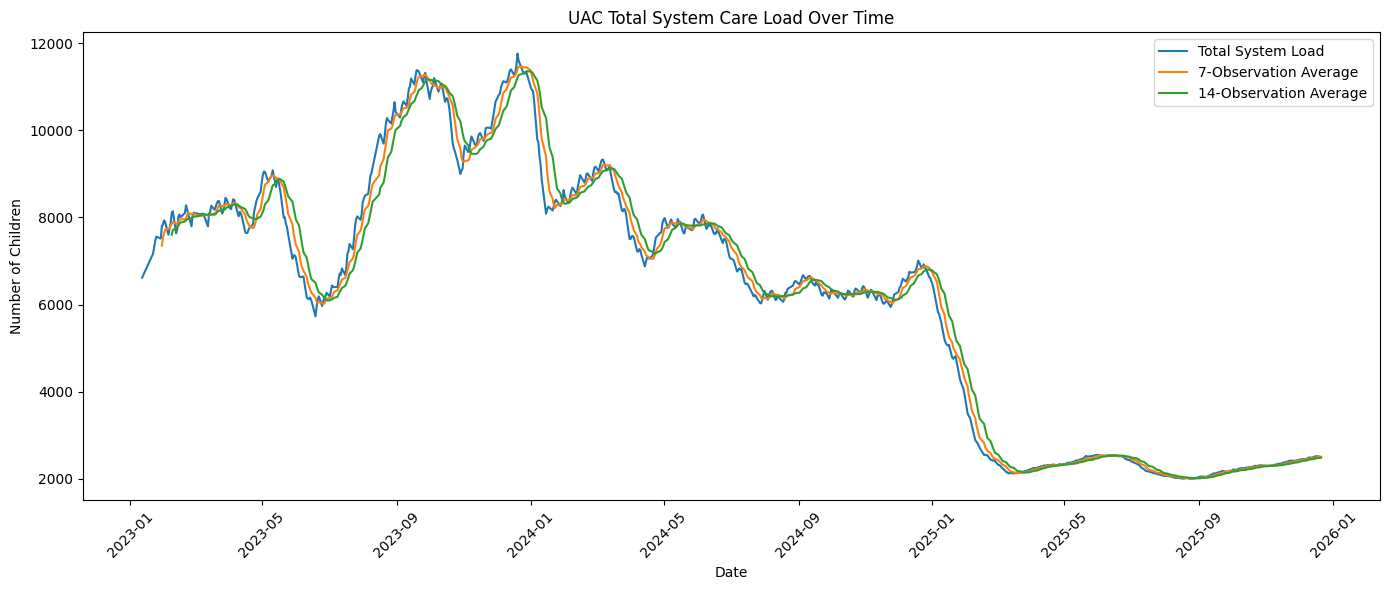

In [39]:
# 1. Reload the dataset to get the uncorrupted original values
file_path = "/content/HHS_Unaccompanied_Alien_Children_Program (1).csv"
df = pd.read_csv(file_path)

# 2. Clean dates and drop empty rows
df["Date"] = pd.to_datetime(df["Date"], errors="coerce")
df = df.dropna(subset=["Date"]).sort_values("Date").reset_index(drop=True)

# 3. Clean CBP custody column
df["Children in CBP custody"] = pd.to_numeric(
    df["Children in CBP custody"], errors="coerce"
)

# 4. Remove commas FIRST, then convert HHS Care to numeric
df["Children in HHS Care"] = df["Children in HHS Care"].astype(str).str.replace(
    ",", ""
)
df["Children in HHS Care"] = pd.to_numeric(
    df["Children in HHS Care"], errors="coerce"
)

# 5. Calculate Total System Load and Rolling Averages
df["Total System Load"] = (
    df["Children in CBP custody"] + df["Children in HHS Care"]
)
df["7-Observation Average"] = (
    df["Total System Load"].rolling(window=7).mean()
)
df["14-Observation Average"] = (
    df["Total System Load"].rolling(window=14).mean()
)

# 6. Plot the chart
plt.figure(figsize=(14, 6))
plt.plot(df["Date"], df["Total System Load"], label="Total System Load")
plt.plot(df["Date"], df["7-Observation Average"], label="7-Observation Average")
plt.plot(
    df["Date"], df["14-Observation Average"], label="14-Observation Average"
)
plt.xlabel("Date")
plt.ylabel("Number of Children")
plt.title("UAC Total System Care Load Over Time")
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

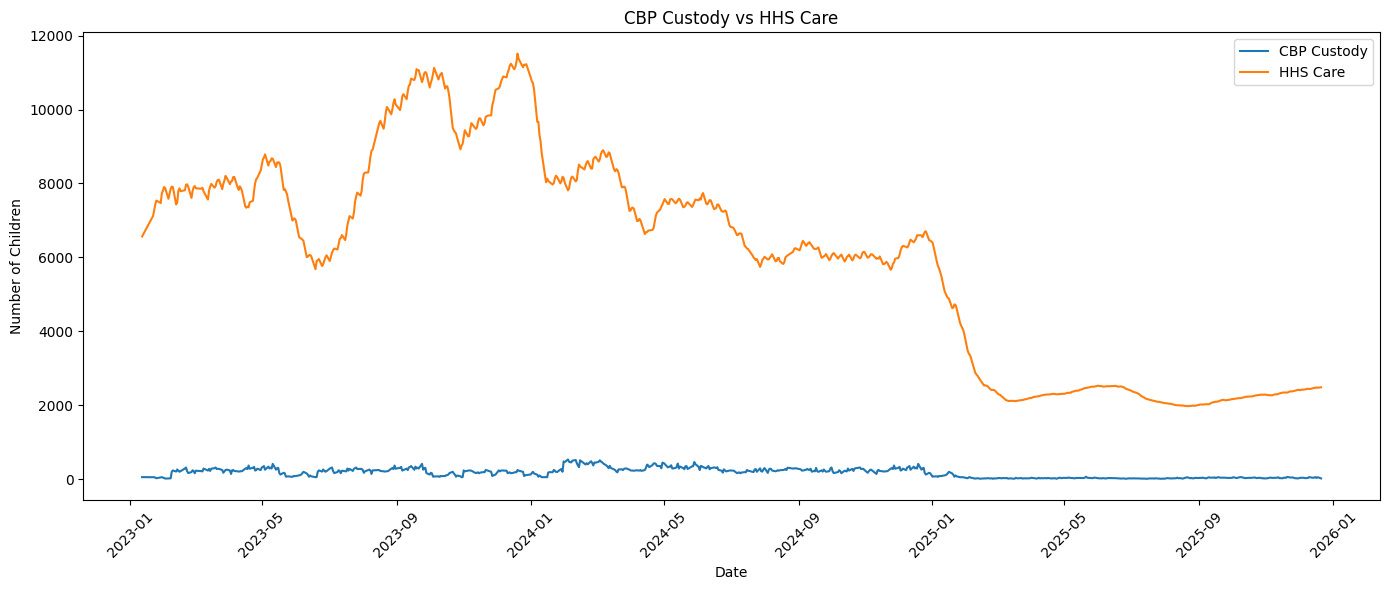

In [40]:
plt.figure(figsize=(14, 6))

plt.plot(
    df["Date"],
    df["Children in CBP custody"],
    label="CBP Custody"
)

plt.plot(
    df["Date"],
    df["Children in HHS Care"],
    label="HHS Care"
)

plt.xlabel("Date")
plt.ylabel("Number of Children")
plt.title("CBP Custody vs HHS Care")

plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()

plt.show()

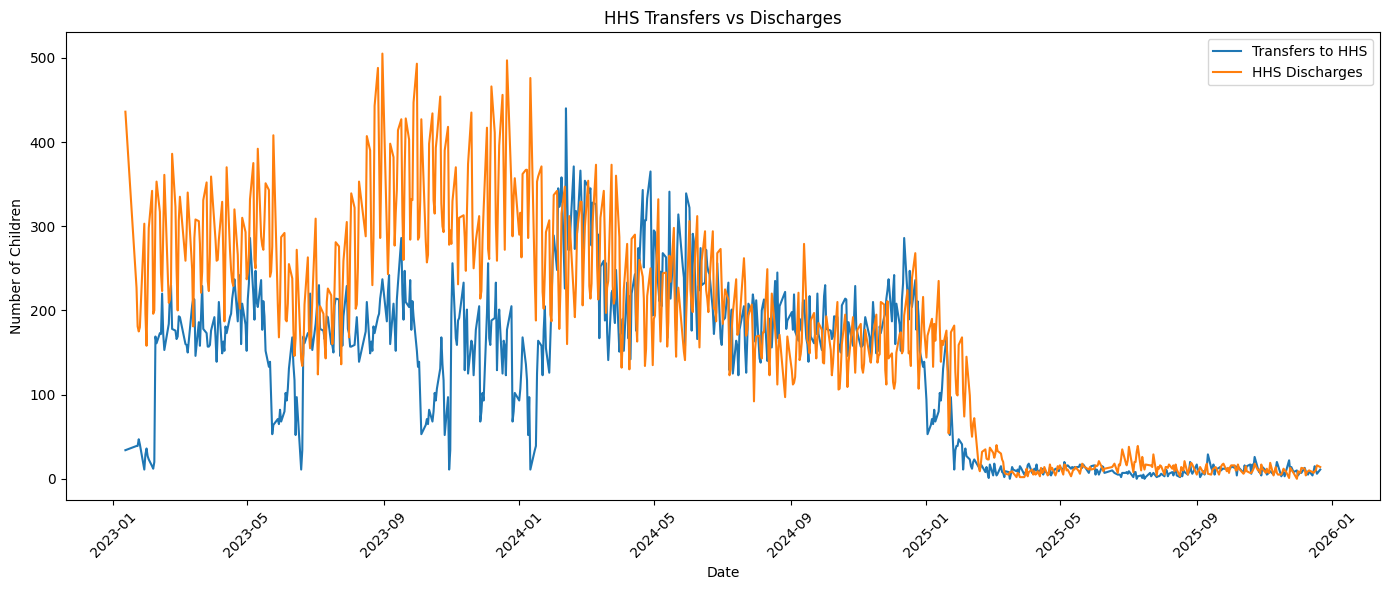

In [41]:
plt.figure(figsize=(14, 6))

plt.plot(
    df["Date"],
    df["Children transferred out of CBP custody"],
    label="Transfers to HHS"
)

plt.plot(
    df["Date"],
    df["Children discharged from HHS Care"],
    label="HHS Discharges"
)

plt.xlabel("Date")
plt.ylabel("Number of Children")
plt.title("HHS Transfers vs Discharges")

plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()

plt.show()

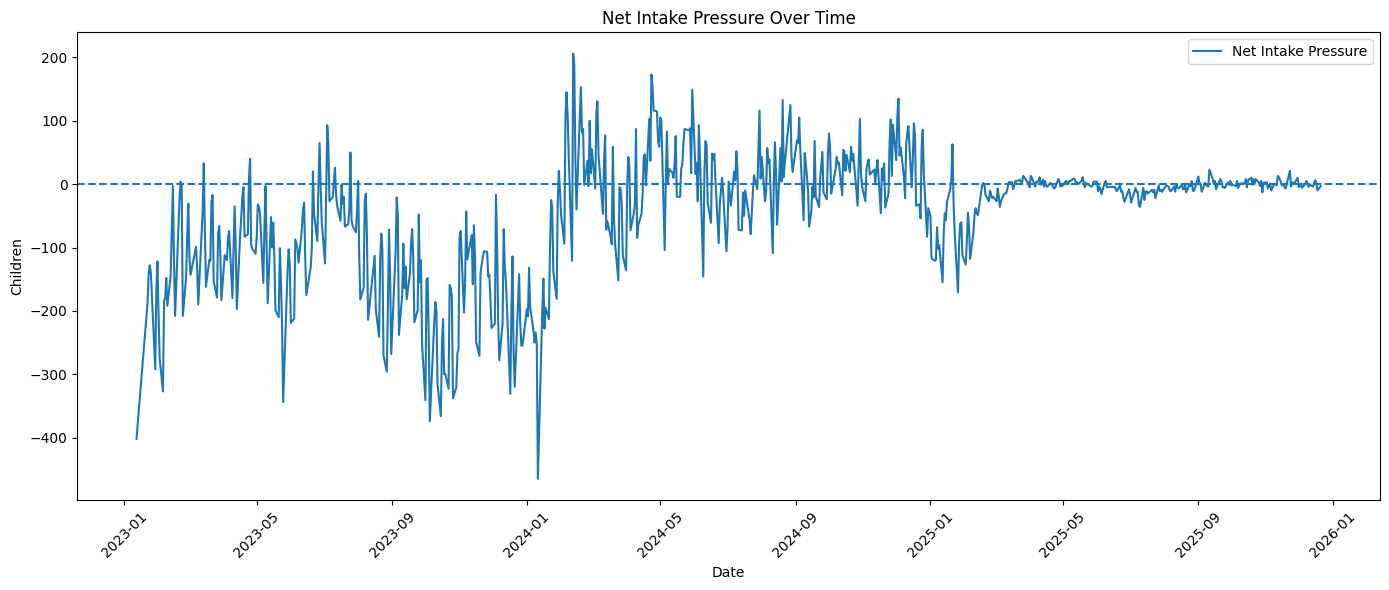

In [42]:
df["Net Intake Pressure"] = (df["Children transferred out of CBP custody"] - df["Children discharged from HHS Care"])

plt.figure(figsize=(14, 6))

plt.plot(
    df["Date"],
    df["Net Intake Pressure"],
    label="Net Intake Pressure"
)

plt.axhline(
    0,
    linestyle="--"
)

plt.xlabel("Date")
plt.ylabel("Children")
plt.title("Net Intake Pressure Over Time")

plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()

plt.show()

In [43]:
df["Year-Month"] = df["Date"].dt.to_period("M")

monthly = df.groupby("Year-Month").agg({
    "Total System Load": "mean",
    "Children in CBP custody": "mean",
    "Children in HHS Care": "mean",
    "Net Intake Pressure": "mean",
    "Children transferred out of CBP custody": "sum",
    "Children discharged from HHS Care": "sum"
}).reset_index()

monthly.head()

,Year-Month,Total System Load,Children in CBP custody,Children in HHS Care,Net Intake Pressure,Children transferred out of CBP custody,Children discharged from HHS Care
0,2023-01,7413.500000,43.875000,7369.625000,-197.500000,276.0,1856.0
1,2023-02,7967.105263,171.315789,7795.789474,-134.000000,2637.0,5183.0
2,2023-03,8190.473684,245.105263,7945.368421,-104.000000,3399.0,5375.0
3,2023-04,8092.857143,250.190476,7842.666667,-81.000000,3967.0,5668.0
4,2023-05,8404.090909,216.954545,8187.136364,-119.727273,3622.0,6256.0


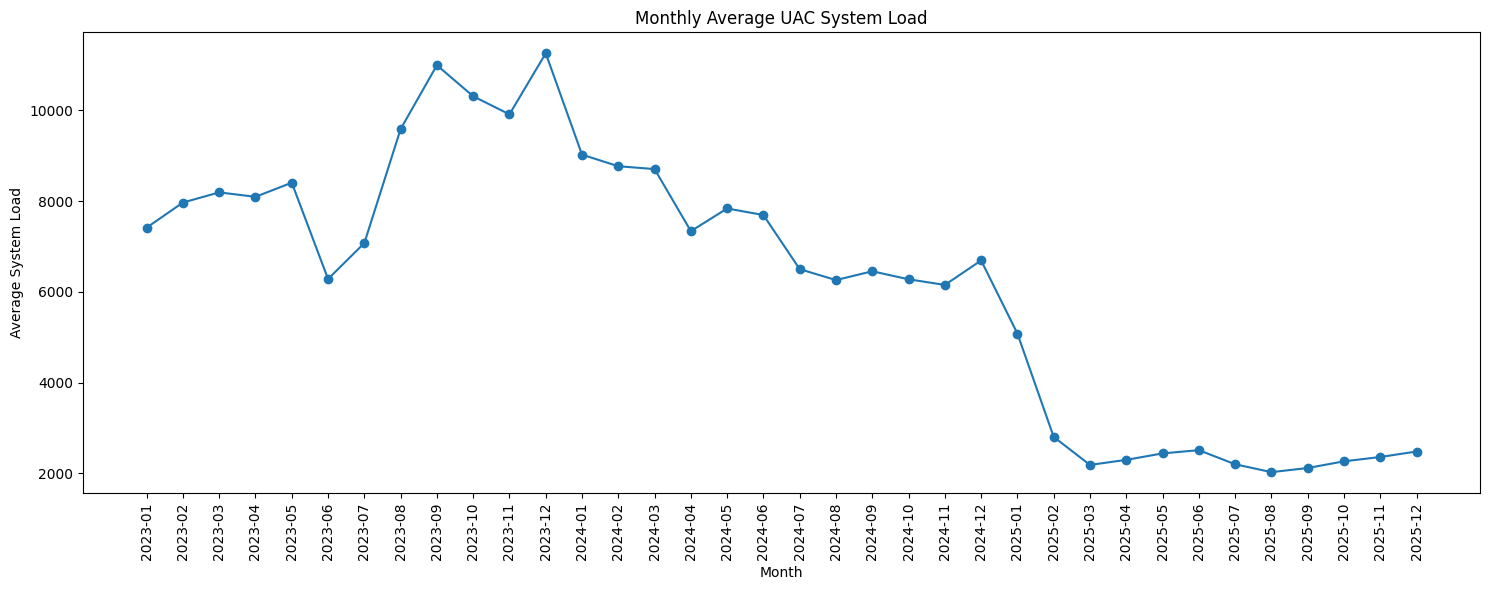

In [44]:
plt.figure(figsize=(15, 6))

plt.plot(
    monthly["Year-Month"].astype(str),
    monthly["Total System Load"],
    marker="o"
)

plt.xlabel("Month")
plt.ylabel("Average System Load")
plt.title("Monthly Average UAC System Load")

plt.xticks(rotation=90)
plt.tight_layout()

plt.show()

In [45]:
df["Discharge Offset Ratio"] = np.where(
    df["Children transferred out of CBP custody"] > 0,
    df["Children discharged from HHS Care"] /
    df["Children transferred out of CBP custody"],
    np.nan
)

print("========== UAC SYSTEM KPI SUMMARY ==========")

print(
    "Average Total System Load:",
    round(df["Total System Load"].mean(), 2)
)

print(
    "Maximum Total System Load:",
    round(df["Total System Load"].max(), 2)
)

print(
    "Minimum Total System Load:",
    round(df["Total System Load"].min(), 2)
)

print(
    "Average Net Intake Pressure:",
    round(df["Net Intake Pressure"].mean(), 2)
)

print(
    "Maximum Net Intake Pressure:",
    round(df["Net Intake Pressure"].max(), 2)
)

print(
    "Average Discharge Offset Ratio:",
    round(df["Discharge Offset Ratio"].mean(), 3)
)

========== UAC SYSTEM KPI SUMMARY ==========
Average Total System Load: 6232.77
Maximum Total System Load: 11762.0
Minimum Total System Load: 2002.0
Average Net Intake Pressure: -44.74
Maximum Net Intake Pressure: 206.0
Average Discharge Offset Ratio: 2.014


In [46]:
import pandas as pd
import numpy as np

# --- Data Preprocessing to ensure 'Total System Load' and other columns exist ---
# Assuming 'file_path' is defined in a previous cell or globally
# If file_path is not defined, it would cause another error. Let's assume it is.
file_path = "/content/HHS_Unaccompanied_Alien_Children_Program (1).csv"
df = pd.read_csv(file_path)

# Clean dates and drop empty rows
df["Date"] = pd.to_datetime(df["Date"], errors="coerce")
df = df.dropna(subset=["Date"]).sort_values("Date").reset_index(drop=True)

# Clean 'Children in CBP custody' column
df["Children in CBP custody"] = pd.to_numeric(
    df["Children in CBP custody"], errors="coerce"
)

# Remove commas FIRST, then convert 'Children in HHS Care' to numeric
df["Children in HHS Care"] = df["Children in HHS Care"].astype(str).str.replace(
    ",", ""
)
df["Children in HHS Care"] = pd.to_numeric(
    df["Children in HHS Care"], errors="coerce"
)

# Calculate Total System Load
df["Total System Load"] = (
    df["Children in CBP custody"] + df["Children in HHS Care"]
)

# Calculate Net Intake Pressure (used later in the print statement)
df["Net Intake Pressure"] = (
    df["Children transferred out of CBP custody"] - df["Children discharged from HHS Care"]
)
# ------------------------------------------------------------------------------

# CAPACITY STRESS ANALYSIS

# Calculate the median system load
median_load = df["Total System Load"].median()

# Define high-load observations
df["Capacity Stress"] = np.where(
    df["Total System Load"] >= median_load,
    "High Load",
    "Normal Load"
)

print("Median System Load:", median_load)

print("\nCapacity Stress Distribution:")
print(df["Capacity Stress"].value_counts())

print("\nHighest Load Observations:")
print(
    df[
        [
            "Date",
            "Total System Load",
            "Children in CBP custody",
            "Children in HHS Care",
            "Net Intake Pressure"
        ]
    ]
    .sort_values("Total System Load", ascending=False)
    .head(10)
)

Median System Load: 6633.5

Capacity Stress Distribution:
Capacity Stress
Normal Load    360
High Load      360
Name: count, dtype: int64

Highest Load Observations:
          Date  Total System Load  Children in CBP custody  \
224 2023-12-20            11762.0                    246.0   
225 2023-12-21            11603.0                    228.0   
223 2023-12-19            11476.0                    185.0   
220 2023-12-14            11399.0                    157.0   
161 2023-09-19            11382.0                    287.0   
162 2023-09-20            11374.0                    310.0   
219 2023-12-13            11373.0                    181.0   
163 2023-09-21            11352.0                    285.0   
226 2023-12-25            11340.0                    196.0   
222 2023-12-18            11337.0                    188.0   

     Children in HHS Care  Net Intake Pressure  
224                 11516               -267.0  
225                 11375               -320.0  
223 

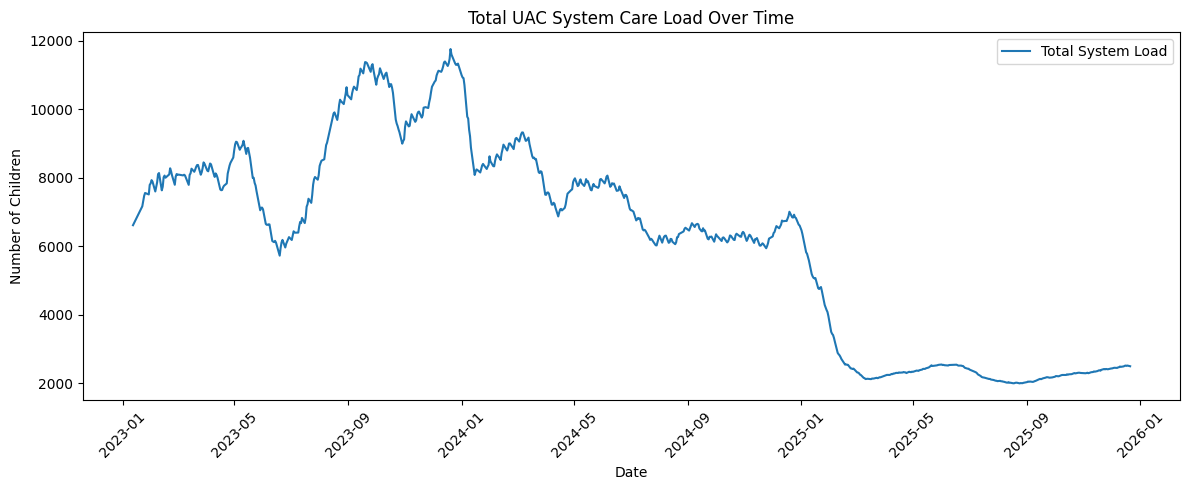

In [51]:
#total system load

plt.figure(figsize=(12,5))

plt.plot(
    df["Date"],
    df["Total System Load"],
    label="Total System Load"
)

plt.xlabel("Date")
plt.ylabel("Number of Children")
plt.title("Total UAC System Care Load Over Time")

plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

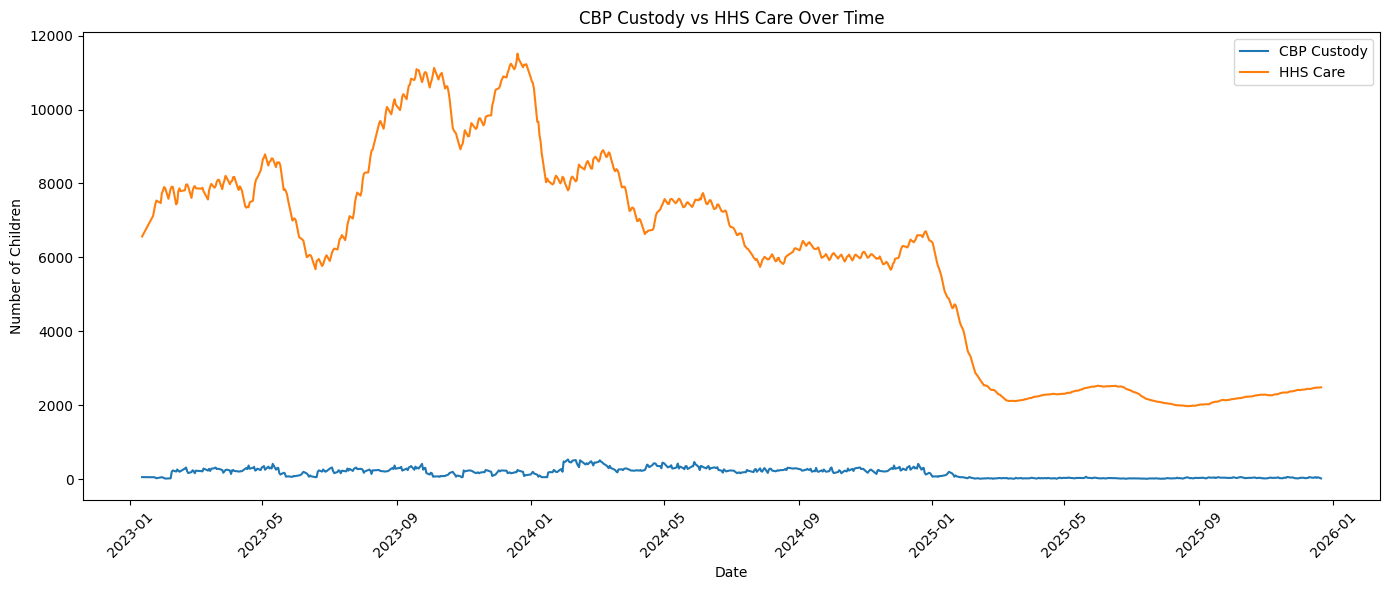

In [48]:
#cbp vs hhs

plt.figure(figsize=(14,6))

plt.plot(
    df["Date"],
    df["Children in CBP custody"],
    label="CBP Custody"
)

plt.plot(
    df["Date"],
    df["Children in HHS Care"],
    label="HHS Care"
)

plt.xlabel("Date")
plt.ylabel("Number of Children")
plt.title("CBP Custody vs HHS Care Over Time")

plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

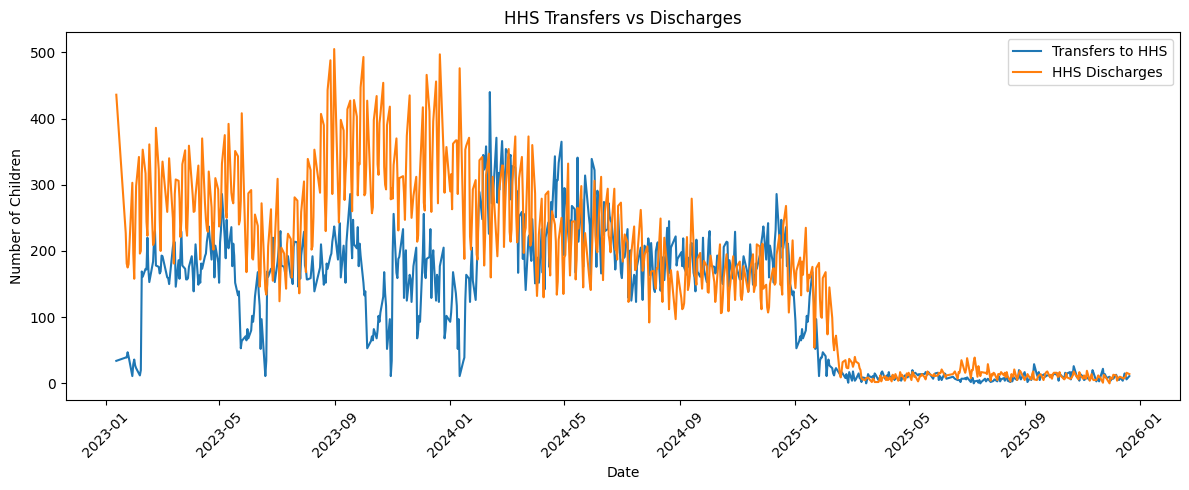

In [52]:
# transfers vs discharge

plt.figure(figsize=(12,5))

plt.plot(
    df["Date"],
    df["Children transferred out of CBP custody"],
    label="Transfers to HHS"
)

plt.plot(
    df["Date"],
    df["Children discharged from HHS Care"],
    label="HHS Discharges"
)

plt.xlabel("Date")
plt.ylabel("Number of Children")
plt.title("HHS Transfers vs Discharges")

plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

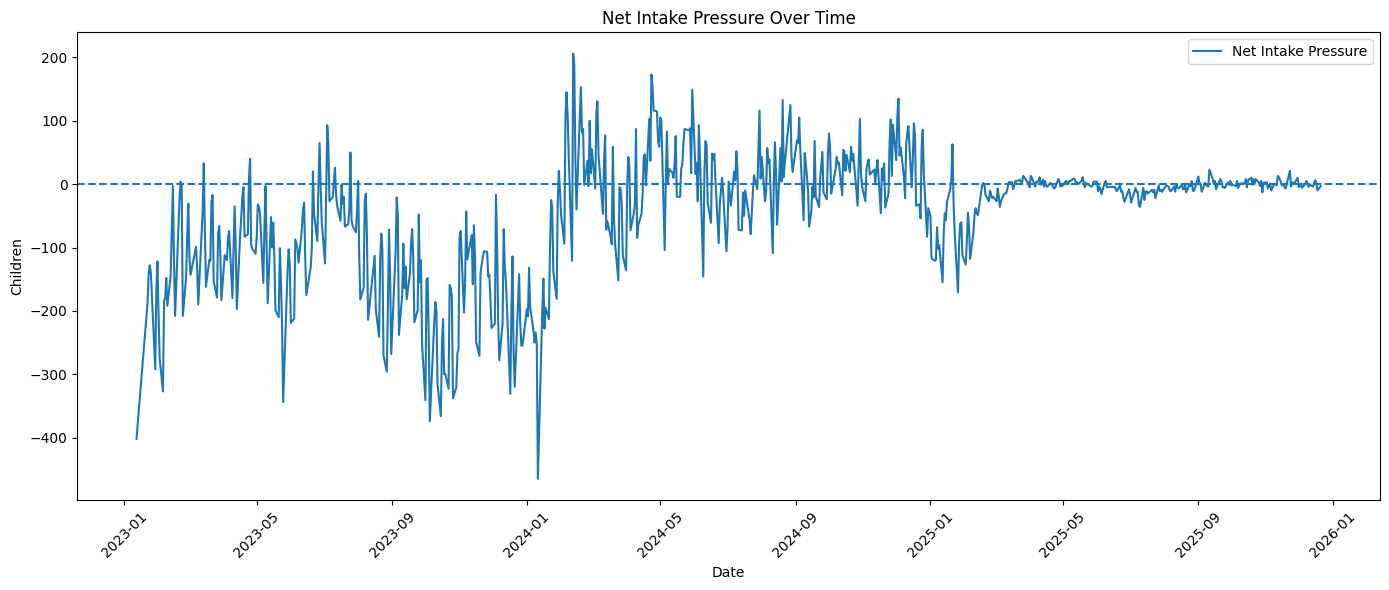

In [53]:
# net intake pressure chart

plt.figure(figsize=(14,6))

plt.plot(
    df["Date"],
    df["Net Intake Pressure"],
    label="Net Intake Pressure"
)

plt.axhline(
    0,
    linestyle="--"
)

plt.xlabel("Date")
plt.ylabel("Children")
plt.title("Net Intake Pressure Over Time")

plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [54]:

# MONTHLY ANALYSIS

df["Year-Month"] = df["Date"].dt.to_period("M")

monthly = df.groupby("Year-Month").agg({
    "Total System Load": "mean",
    "Children in CBP custody": "mean",
    "Children in HHS Care": "mean",
    "Net Intake Pressure": "mean",
    "Children transferred out of CBP custody": "sum",
    "Children discharged from HHS Care": "sum"
}).reset_index()

print(monthly.head())

  Year-Month  Total System Load  Children in CBP custody  \
0    2023-01        7413.500000                43.875000   
1    2023-02        7967.105263               171.315789   
2    2023-03        8190.473684               245.105263   
3    2023-04        8092.857143               250.190476   
4    2023-05        8404.090909               216.954545   

   Children in HHS Care  Net Intake Pressure  \
0           7369.625000          -197.500000   
1           7795.789474          -134.000000   
2           7945.368421          -104.000000   
3           7842.666667           -81.000000   
4           8187.136364          -119.727273   

   Children transferred out of CBP custody  Children discharged from HHS Care  
0                                    276.0                             1856.0  
1                                   2637.0                             5183.0  
2                                   3399.0                             5375.0  
3                             

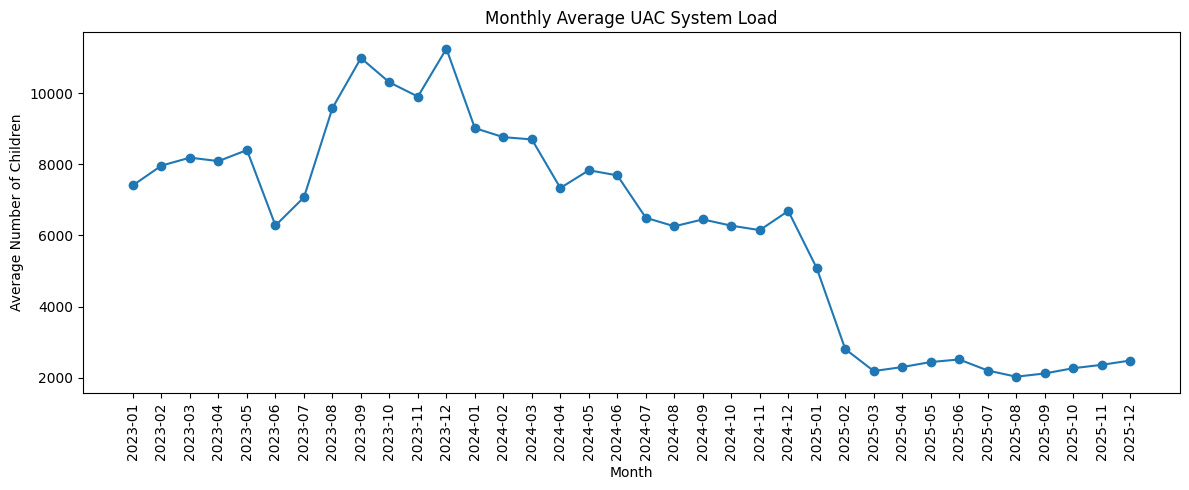

In [56]:
# monthly ana

plt.figure(figsize=(12,5))

plt.plot(
    monthly["Year-Month"].astype(str),
    monthly["Total System Load"],
    marker="o"
)

plt.xlabel("Month")
plt.ylabel("Average Number of Children")
plt.title("Monthly Average UAC System Load")

plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

In [58]:
# FINAL PROJECT RESULTS

# Ensure 'Discharge Offset Ratio' is calculated
df["Discharge Offset Ratio"] = np.where(
    df["Children transferred out of CBP custody"] > 0,
    df["Children discharged from HHS Care"] /
    df["Children transferred out of CBP custody"],
    np.nan
)

results = {
    "Average Total System Load":
        df["Total System Load"].mean(),

    "Maximum Total System Load":
        df["Total System Load"].max(),

    "Minimum Total System Load":
        df["Total System Load"].min(),

    "Average Net Intake Pressure":
        df["Net Intake Pressure"].mean(),

    "Maximum Net Intake Pressure":
        df["Net Intake Pressure"].max(),

    "Average Discharge Offset Ratio":
        df["Discharge Offset Ratio"].mean(),

    "Number of Observations":
        len(df),

    "Highest Load Date":
        df.loc[df["Total System Load"].idxmax(), "Date"]
}

for key, value in results.items():
    print(key, ":", value)

Average Total System Load : 6232.769444444444
Maximum Total System Load : 11762.0
Minimum Total System Load : 2002.0
Average Net Intake Pressure : -44.73888888888889
Maximum Net Intake Pressure : 206.0
Average Discharge Offset Ratio : 2.013512376809794
Number of Observations : 720
Highest Load Date : 2023-12-20 00:00:00


In [59]:
df.to_csv(
    "UAC_Cleaned_Analytics_Dataset.csv",
    index=False
)

print("Cleaned dataset saved successfully!")

Cleaned dataset saved successfully!


In [60]:
from google.colab import files

files.download("UAC_Cleaned_Analytics_Dataset.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>


FORECASTING

In [61]:


from sklearn.linear_model import LinearRegression
import numpy as np
import pandas as pd

forecast_df = df[[
    "Date",
    "Total System Load"
]].dropna().copy()

# Convert dates into numerical values
forecast_df["Days"] = (
    forecast_df["Date"] - forecast_df["Date"].min()
).dt.days

X = forecast_df[["Days"]]
y = forecast_df["Total System Load"]

model = LinearRegression()

model.fit(X, y)

print("Forecasting model created successfully.")
print("Model coefficient:", model.coef_[0])
print("Model intercept:", model.intercept_)

Forecasting model created successfully.
Model coefficient: -7.962380892768478
Model intercept: 10542.242219720116


In [62]:

# 30-OBSERVATION FORECAST

last_day = forecast_df["Days"].max()

future_days = np.arange(
    last_day + 1,
    last_day + 31
)

future_X = pd.DataFrame({
    "Days": future_days
})

future_predictions = model.predict(future_X)

forecast_dates = pd.date_range(
    start=forecast_df["Date"].max() + pd.Timedelta(days=1),
    periods=30
)

forecast_result = pd.DataFrame({
    "Date": forecast_dates,
    "Forecasted System Load": future_predictions
})

print(forecast_result)

         Date  Forecasted System Load
0  2025-12-22             1982.682760
1  2025-12-23             1974.720379
2  2025-12-24             1966.757998
3  2025-12-25             1958.795617
4  2025-12-26             1950.833236
5  2025-12-27             1942.870856
6  2025-12-28             1934.908475
7  2025-12-29             1926.946094
8  2025-12-30             1918.983713
9  2025-12-31             1911.021332
10 2026-01-01             1903.058951
11 2026-01-02             1895.096570
12 2026-01-03             1887.134189
13 2026-01-04             1879.171808
14 2026-01-05             1871.209427
15 2026-01-06             1863.247047
16 2026-01-07             1855.284666
17 2026-01-08             1847.322285
18 2026-01-09             1839.359904
19 2026-01-10             1831.397523
20 2026-01-11             1823.435142
21 2026-01-12             1815.472761
22 2026-01-13             1807.510380
23 2026-01-14             1799.547999
24 2026-01-15             1791.585619
25 2026-01-1

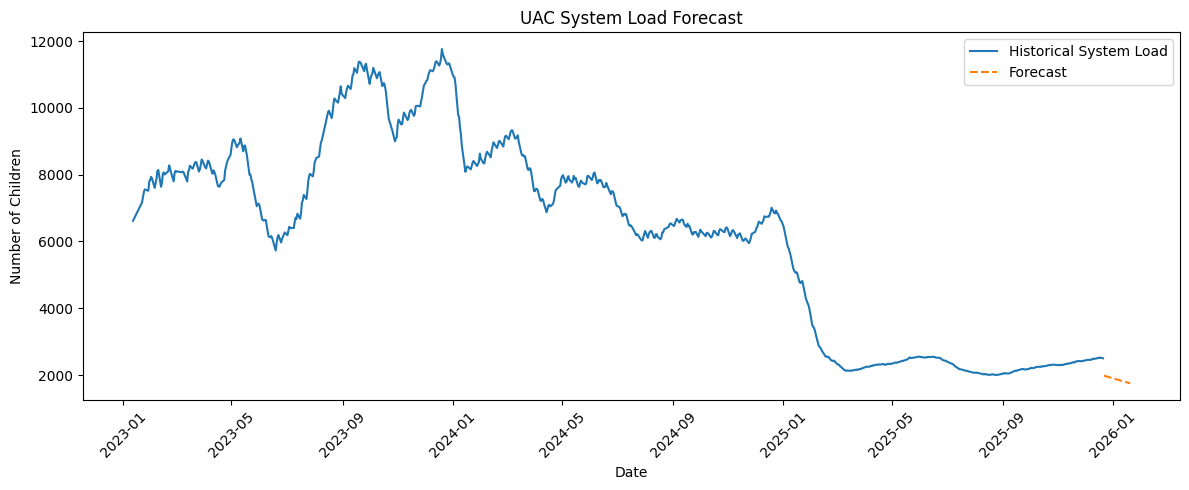

In [64]:
# FORCAST CHART


plt.figure(figsize=(12,5))

plt.plot(
    forecast_df["Date"],
    forecast_df["Total System Load"],
    label="Historical System Load"
)

plt.plot(
    forecast_result["Date"],
    forecast_result["Forecasted System Load"],
    linestyle="--",
    label="Forecast"
)

plt.xlabel("Date")
plt.ylabel("Number of Children")
plt.title("UAC System Load Forecast")

plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

KPI TABLE

In [65]:
kpi_summary = pd.DataFrame({
    "KPI": [
        "Average Total System Load",
        "Maximum Total System Load",
        "Minimum Total System Load",
        "Average Net Intake Pressure",
        "Maximum Net Intake Pressure",
        "Average Discharge Offset Ratio"
    ],

    "Value": [
        round(df["Total System Load"].mean(), 2),
        round(df["Total System Load"].max(), 2),
        round(df["Total System Load"].min(), 2),
        round(df["Net Intake Pressure"].mean(), 2),
        round(df["Net Intake Pressure"].max(), 2),
        round(df["Discharge Offset Ratio"].mean(), 3)
    ]
})

kpi_summary

,KPI,Value
0,Average Total System Load,6232.770
1,Maximum Total System Load,11762.000
2,Minimum Total System Load,2002.000
3,Average Net Intake Pressure,-44.740
4,Maximum Net Intake Pressure,206.000
5,Average Discharge Offset Ratio,2.014


In [67]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

# Predictions on historical data
historical_predictions = model.predict(X)

mae = mean_absolute_error(y, historical_predictions)
rmse = np.sqrt(mean_squared_error(y, historical_predictions))
r2 = r2_score(y, historical_predictions)

print(" MODEL EVALUATION ")
print("MAE:", round(mae, 2))
print("RMSE:", round(rmse, 2))
print("R² Score:", round(r2, 3))

 MODEL EVALUATION 
MAE: 1353.27
RMSE: 1593.62
R² Score: 0.701


In [69]:
forecast_result.to_csv(
    "UAC_30_Day_Forecast.csv",
    index=False
)

print("Forecast file saved successfully!")


Forecast file saved successfully!


In [70]:
from google.colab import files

files.download("UAC_30_Day_Forecast.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>